# 01 · Preprocess EyePACS / APTOS / Messidor-2 into 768 px shards

**Kaggle settings:** Accelerator **None** (CPU, uses no GPU quota). Internet not needed.
Run with *Save Version → Save & Run All* so the output persists. Expected runtime is roughly 1–2 h, mostly I/O.

**Inputs to attach** (edit `SRC` / `LABELS` below if your mount paths differ):
| role | Kaggle source |
|---|---|
| EyePACS train + test images (original ~82 GB split zips) | competition `diabetic-retinopathy-detection` (accept its rules first) |
| EyePACS 2015 **test labels** (released after the competition) | dataset `benjaminwarner/resized-2015-2019-blindness-detection-images` → `labels/testLabels15.csv` |
| APTOS 2019 | competition `aptos2019-blindness-detection` |
| Messidor-2 images | dataset `xyaustin/messidor2` |
| Messidor-2 adjudicated grades (Krause et al. 2018) | dataset `google-brain/messidor2-dr-grades` |

**What it does**
1. Streams every image straight out of the split zip archives. Nothing is extracted to disk, because 82 GB would not fit.
   JPEGs are decoded at reduced scale through libjpeg's DCT scaling, which makes decoding about 4× faster.
2. Tight-crops the fundus disc, pads it to a centred square and resizes to **768 px**. Training runs at 512 px by default, where microaneurysms are about 2–4 px.
   Keeping 768 px leaves room to train at 640–768 later. Ben Graham / CLAHE enhancement happens at load time in notebook 02, so it can be ablated.
3. Label-noise cleanup on APTOS. The dataset contains near-duplicate images, some with conflicting grades.
   These are clustered by perceptual hash: groups with a conflicting grade are dropped, and only one copy of a consistent group is kept.
4. Makes a **patient-grouped** stratified train/val split, so the left and right eye of one patient never land on different sides.

**Output** (`/kaggle/working`): `eyepacs_train.zip`, `eyepacs_test.zip`, `aptos.zip`, `messidor2.zip` (JPEG, stored uncompressed) and `labels.csv`.
The images are sharded into zips because Kaggle notebook output has a ~500-file limit.

In [1]:
import bisect, functools, io, itertools, multiprocessing as mp, os, zipfile
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
from PIL import Image
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold

INPUT = Path(os.environ.get('DR_INPUT', '/kaggle/input'))
OUT = Path(os.environ.get('DR_WORK', '/kaggle/working'))
SIZE = 768        # stored resolution
QUALITY = 95      # JPEG quality of stored shards (~10 GB total, under the 20 GB output limit)
DUP_BITS = 6      # max Hamming distance (of 256 bits) for two APTOS images to count as duplicates
VAL_FOLDS = 10    # val = 1/VAL_FOLDS of the labelled training pool
EXTS = {'.jpeg', '.jpg', '.png', '.tif', '.tiff'}

# Image source per shard: a directory, a .zip, or the first part (.001) of a split zip.
# If reading the original split zips fails, point the eyepacs entries at
# INPUT/'resized-2015-2019-blindness-detection-images/resized train 15' (and 'resized test 15'). Those images are already ~1024 px.

# /kaggle/input/competitions/aptos2019-blindness-detection
# /kaggle/input/competitions/diabetic-retinopathy-detection
# /kaggle/input/datasets/xyaustin/messidor2
# /kaggle/input/datasets/google-brain/messidor2-dr-grades
# /kaggle/input/datasets/benjaminwarner/resized-2015-2019-blindness-detection-images

SRC = {
    'eyepacs_train': INPUT / 'competitions/diabetic-retinopathy-detection/train.zip.001',
    'eyepacs_test': INPUT / 'competitions/diabetic-retinopathy-detection/test.zip.001',
    'aptos': INPUT / 'competitions/aptos2019-blindness-detection/train_images',
    'messidor2': INPUT / 'datasets/xyaustin/messidor2/messidor-2/images',
}
LABELS = {
    'eyepacs_train': INPUT / 'competitions/diabetic-retinopathy-detection/trainLabels.csv.zip',
    'eyepacs_test': INPUT / 'datasets/benjaminwarner/resized-2015-2019-blindness-detection-images/labels/testLabels15.csv',
    'aptos': INPUT / 'competitions/aptos2019-blindness-detection/train.csv',
    'messidor2': INPUT / 'datasets/google-brain/messidor2-dr-grades/messidor_data.csv',
}
SPLIT = {'eyepacs_train': 'train', 'aptos': 'train', 'eyepacs_test': 'test', 'messidor2': 'external'}
OUT.mkdir(parents=True, exist_ok=True)

In [2]:
class MultiPart(io.RawIOBase):
    """Seekable read-only view over x.zip.001, x.zip.002, ... as one file, so zipfile can read members in place."""

    def __init__(self, first):
        first = Path(first)
        self.parts = sorted(first.parent.glob(first.name[:-3] + '*'))
        self.starts = list(itertools.accumulate((p.stat().st_size for p in self.parts), initial=0))
        self.fhs = [open(p, 'rb') for p in self.parts]
        self.pos = 0

    def readable(self): return True
    def seekable(self): return True
    def tell(self): return self.pos

    def seek(self, off, whence=0):
        self.pos = (off, self.pos + off, self.starts[-1] + off)[whence]
        return self.pos

    def readinto(self, b):
        i = bisect.bisect_right(self.starts, self.pos) - 1
        if i >= len(self.parts):
            return 0
        f = self.fhs[i]
        f.seek(self.pos - self.starts[i])
        n = f.readinto(memoryview(b)[: self.starts[i + 1] - self.pos])
        self.pos += n
        return n


@functools.cache
def _zip(path, pid):  # one handle per process: forked workers must not share file offsets
    f = io.BufferedReader(MultiPart(path), 1 << 20) if str(path).endswith('.001') else open(path, 'rb')
    return zipfile.ZipFile(f)


def list_images(src):
    if src.is_dir():
        return sorted(str(p) for p in src.iterdir() if p.suffix.lower() in EXTS)
    return [n for n in _zip(src, os.getpid()).namelist() if Path(n).suffix.lower() in EXTS]


def read_bytes(src, name):
    return Path(name).read_bytes() if src.is_dir() else _zip(src, os.getpid()).read(name)


def load_labels(shard):
    df = pd.read_csv(LABELS[shard])  # pandas reads single-file .csv.zip directly
    if shard.startswith('eyepacs'):
        df = df.rename(columns={'image': 'stem', 'level': 'grade'})
    elif shard == 'aptos':
        df = df.rename(columns={'id_code': 'stem', 'diagnosis': 'grade'})
    else:  # Messidor-2: adjudicated ICDR grade; drop the few ungradable images
        df = df[df.adjudicated_gradable == 1].rename(columns={'image_id': 'stem', 'adjudicated_dr_grade': 'grade'})
        df['stem'] = df.stem.str.rsplit('.', n=1).str[0]
    return df.assign(key=df.stem.str.lower())[['key', 'grade']]

In [3]:
def decode(data, size=SIZE):
    im = Image.open(io.BytesIO(data))
    im.draft('RGB', (size, size))  # JPEG only: decode at the smallest 1/2^k scale still >= size
    return np.asarray(im.convert('RGB'))


def crop_fundus(img, size=SIZE):
    """Tight-crop the fundus disc, pad to a centred square, resize. None if no fundus is found."""
    mask = img.max(2) > 15
    rows, cols = np.flatnonzero(mask.mean(1) > 0.02), np.flatnonzero(mask.mean(0) > 0.02)
    if len(rows) < 32 or len(cols) < 32:
        return None
    img = img[rows[0]:rows[-1] + 1, cols[0]:cols[-1] + 1]
    h, w = img.shape[:2]
    d = max(h, w)
    sq = np.zeros((d, d, 3), np.uint8)
    sq[(d - h) // 2:(d - h) // 2 + h, (d - w) // 2:(d - w) // 2 + w] = img
    return cv2.resize(sq, (size, size), interpolation=cv2.INTER_AREA)


def dhash(img, n=16):
    g = cv2.resize(cv2.cvtColor(img, cv2.COLOR_RGB2GRAY), (n + 1, n), interpolation=cv2.INTER_AREA)
    return np.packbits(g[:, 1:] > g[:, :-1]).tobytes().hex()


def process(job):
    src, name = job
    stem = Path(name).stem
    try:
        img = crop_fundus(decode(read_bytes(src, name)))
    except Exception as e:  # corrupt / truncated file: skip it, keep going
        print('decode failed', name, e)
        img = None
    if img is None:
        return stem, None, None
    jpg = cv2.imencode('.jpg', cv2.cvtColor(img, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, QUALITY])[1]
    return stem, jpg.tobytes(), {'mean': round(float(img.mean()), 1), 'dhash': dhash(img)}

In [4]:
rows = []
for shard, src in SRC.items():
    if not (src.exists() and LABELS[shard].exists()):
        print(f'SKIP {shard}: missing {src if not src.exists() else LABELS[shard]}')
        continue
    labels = load_labels(shard)
    want = set(labels.key)
    jobs = [(src, n) for n in list_images(src) if Path(n).stem.lower() in want]
    print(f'{shard}: {len(jobs)} labelled images of {len(want)} labels')
    failed = 0
    with mp.get_context('fork').Pool(os.cpu_count()) as pool, \
            zipfile.ZipFile(OUT / f'{shard}.zip', 'w', zipfile.ZIP_STORED) as zf:
        for i, (stem, jpg, meta) in enumerate(pool.imap_unordered(process, jobs, chunksize=8)):
            if jpg is None:
                failed += 1
                continue
            zf.writestr(f'{stem}.jpg', jpg)
            rows.append({'shard': shard, 'stem': stem, 'key': stem.lower(), **meta})
            if i % 5000 == 0:
                print(f'  {i}/{len(jobs)}')
    print(f'  done, {failed} without a detectable fundus (skipped)')

df = pd.DataFrame(rows)
df = df.merge(pd.concat([load_labels(s).assign(shard=s) for s in df.shard.unique()]), on=['shard', 'key'])
df['dataset'] = df.shard.str.split('_').str[0]
df['split'] = df.shard.map(SPLIT)
df['patient'] = np.where(df.dataset == 'eyepacs', df.shard + '_' + df.stem.str.split('_').str[0], df.dataset + '_' + df.stem)
df['keep'] = True

eyepacs_train: 35126 labelled images of 35126 labels
  0/35126
  5000/35126
  10000/35126
  15000/35126
  20000/35126
  25000/35126
  30000/35126
  35000/35126
  done, 5 without a detectable fundus (skipped)
eyepacs_test: 53576 labelled images of 53576 labels
  0/53576
  5000/53576
  10000/53576
  15000/53576
  20000/53576
  25000/53576
  30000/53576
  35000/53576
  40000/53576
  45000/53576
  50000/53576
  done, 5 without a detectable fundus (skipped)
aptos: 3662 labelled images of 3662 labels
  0/3662
  done, 0 without a detectable fundus (skipped)
messidor2: 1744 labelled images of 1744 labels
  0/1744
  done, 0 without a detectable fundus (skipped)


## Label noise: APTOS near-duplicates
APTOS contains duplicate images, some of them graded differently. Duplicates are found by perceptual hash (256-bit dHash) and grouped into connected components.
A group whose grades **conflict** is dropped, because its label is unreliable. A group whose grades agree keeps one copy, so duplicates can't leak across the val split or get extra weight.

In [5]:
def dup_groups(hashes, max_bits=DUP_BITS):
    b = np.unpackbits(np.stack([np.frombuffer(bytes.fromhex(h), np.uint8) for h in hashes]), axis=1).astype(np.float32)
    dist = b @ (1 - b).T
    i, j = np.nonzero(np.triu(dist + dist.T <= max_bits, 1))
    return connected_components(coo_matrix((np.ones(len(i)), (i, j)), shape=(len(b),) * 2), directed=False)[1]


a = df.dataset == 'aptos'
if a.any():
    df.loc[a, 'dup_group'] = dup_groups(df.loc[a, 'dhash'].tolist())
    g = df[a].groupby('dup_group').grade
    conflict = g.transform('nunique') > 1
    df.loc[a, 'keep'] = ~conflict & ~df[a].duplicated('dup_group')
    df.loc[a, 'patient'] = 'aptos_g' + df.loc[a, 'dup_group'].astype(int).astype(str)
    sizes = g.transform('size')
    print(f'APTOS: {int((sizes > 1).sum())} images in duplicate groups; '
          f'{int(conflict.sum())} dropped for conflicting grades; {int((~df.loc[a, "keep"]).sum())} dropped in total')

APTOS: 268 images in duplicate groups; 79 dropped for conflicting grades; 175 dropped in total


## Patient-grouped stratified validation split
Stratification is by dataset × grade, so val has the natural class mix of both sources. That matters because the decision thresholds are tuned on val.

In [6]:
tr = df[(df.split == 'train') & df.keep]
y = tr.dataset.map({'eyepacs': 0, 'aptos': 5}) + tr.grade
_, val_idx = next(StratifiedGroupKFold(VAL_FOLDS, shuffle=True, random_state=42).split(tr, y, tr.patient))
df.loc[tr.index[val_idx], 'split'] = 'val'

df.drop(columns='key').to_csv(OUT / 'labels.csv', index=False)
print(pd.crosstab([df.split, df.dataset], df.grade, margins=True))
print('dropped:', (~df.keep).sum())

grade                 0.0   1.0    2.0   3.0   4.0    All
split    dataset                                         
external messidor2   1017   270    347    75    35   1744
test     eyepacs    39529  3762   7860  1214  1206  53571
train    aptos       1618   332    914   174   273   3311
         eyepacs    23255  2209   4754   758   635  31611
val      aptos        187    38     85    19    22    351
         eyepacs     2552   232    538   115    73   3510
All                 68158  6843  14498  2355  2244  94098
dropped: 175


### Sanity check: a few stored images and duplicate pairs

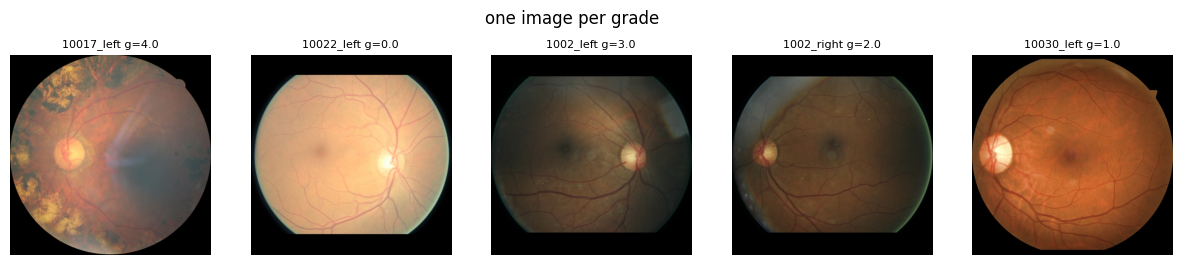

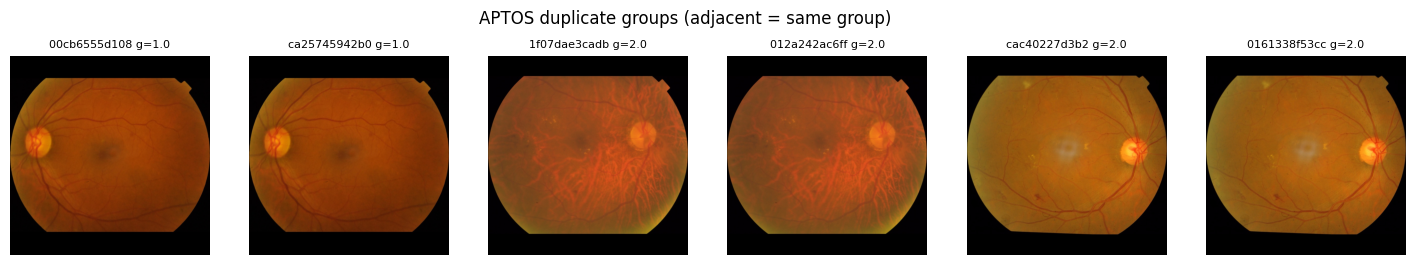

In [7]:
import matplotlib.pyplot as plt

def show(shard_stems, title):
    fig, ax = plt.subplots(1, len(shard_stems), figsize=(3 * len(shard_stems), 3))
    for a_, (shard, stem, g) in zip(np.atleast_1d(ax), shard_stems):
        with zipfile.ZipFile(OUT / f'{shard}.zip') as z:
            a_.imshow(cv2.imdecode(np.frombuffer(z.read(f'{stem}.jpg'), np.uint8), cv2.IMREAD_COLOR)[..., ::-1])
        a_.set_title(f'{stem[:14]} g={g}', fontsize=8)
        a_.axis('off')
    fig.suptitle(title)
    plt.show()

ex = df[df.keep].groupby('grade').head(1)
show(list(zip(ex.shard, ex.stem, ex.grade)), 'one image per grade')
if a.any():
    d = df[a]
    dup = d[d.groupby('dup_group').grade.transform('size') > 1].sort_values('dup_group').head(6)
    if len(dup):
        show(list(zip(dup.shard, dup.stem, dup.grade)), 'APTOS duplicate groups (adjacent = same group)')